In [1]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

In [3]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")
# display(df_avg.head())

In [4]:
# Data preprocessing
def prepare_cluster(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    # Replace observations with |value| > 40 with NaN
    data = data.mask(data.abs() > 40)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(
        start=data.columns.min(),
        end=data.columns.max(),
        freq="D"
    )

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = prepare_cluster(df_avg)
minimum = prepare_cluster(df_min)
maximum = prepare_cluster(df_max)

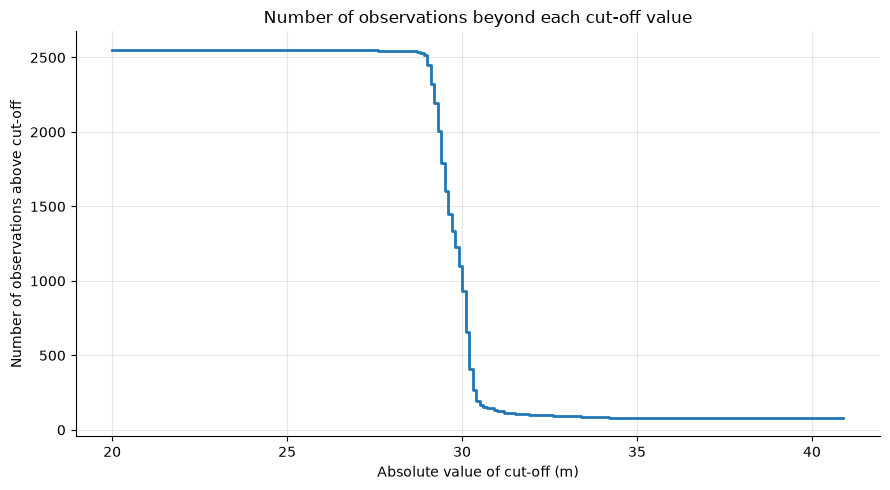

In [5]:
# Identifying a sutable choice for cutt=off
X_avg = df_avg.drop(columns = ['County', 'Station_Name', 'Observation_ID'])
X_min = df_min.drop(columns = ['County', 'Station_Name', 'Observation_ID'])
X_max = df_max.drop(columns = ['County', 'Station_Name', 'Observation_ID'])
cutoff_in_m = np.arange(20, 41, 0.1)
abs_avg = np.abs(np.asarray(X_avg))

counts = [(abs_avg > c).sum() for c in cutoff_in_m]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cutoff_in_m, counts, linewidth=2, drawstyle="steps-post")
ax.set_xlabel("Absolute value of cut-off (m)")
ax.set_ylabel("Number of observations above cut-off")
ax.set_title("Number of observations beyond each cut-off value")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
from numpy.lib.stride_tricks import sliding_window_view
# Creating a new df that can be used to predict whether or not a flood will happen on the next day, based on the water levels of the preceding seven days.
def valid_7day(df):
    """
    Inputs: The preprocessed data frame of water levels
    ---
    Outputs: new df outlining all valid 7 day periods with next day also valid, also reports associated ID and week start date
    
    """
    numeric_vals = df.to_numpy(float) # Extracts the data in df
    dates = df.index                  # Extracts the day lables

    period = sliding_window_view(numeric_vals, 8, axis=0)  
    # np function which runs through data highlighting every 8 day window
    # period is shaped as [the day, the ID, the 8 day window of readings]
    # (Note: for the the 8 day window of readings argument we are dating 'forwards'- which is why we get less days than in the original df, removes last 7 days of data set)]
    
    nan_present = ~np.isnan(period).any(axis=2) # goes through all period and marks False where NaN present 
    # (Note: ~ flips True to False and vise versa so we make NaN as False)

    # We name ID and start date for the nan_present that have NO falses (ie ID and start date for the 8 day periods with no NaN in them)
    ID_name, date_start_name = np.nonzero(nan_present.T)
    valid_periods = period[date_start_name, ID_name, :] # indexing these valid periods 

    # Created df for output
    valid_7day = pd.DataFrame({
        "ID": df.columns[ID_name],
        "Week starting": dates[date_start_name],
        "Day 1": valid_periods[2][0],
        "Day 2": valid_periods[2][1],
        "Day 3": valid_periods[2][2],
        "Day 4": valid_periods[2][3],
        "Day 5": valid_periods[2][4],
        "Day 6": valid_periods[2][5],
        "Day 7": valid_periods[2][6],
        "Next Day": valid_periods[2][7]
    })
    
    return valid_7day

# Testing it works
display(valid_7day(avg))
print(f"Have we successfully got no NaNs? {valid_7day(avg).shape == valid_7day(avg).dropna().shape}")

display(valid_7day(minimum))
print(f"Have we successfully got no NaNs? {valid_7day(minimum).shape == valid_7day(minimum).dropna().shape}")

display(valid_7day(maximum))
print(f"Have we successfully got no NaNs? {valid_7day(maximum).shape == valid_7day(maximum).dropna().shape}")

# (Note: the dimensions of these df will be different since the cut-off range will effect min and max data differently)

,ID,Week starting,Day 1,Day 2,Day 3,Day 4,Day 5,Day 6,Day 7,Next Day
0,0,2017-03-31,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195
1,0,2017-04-01,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195
2,0,2017-04-02,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195
3,0,2017-04-03,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195
4,0,2017-04-04,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195
...,...,...,...,...,...,...,...,...,...,...
1166176,391,2026-09-27,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195
1166177,391,2026-09-28,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195
1166178,391,2026-09-29,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195
1166179,391,2026-09-30,0.22,0.212,0.208,0.204,0.202,0.199,0.197,0.195


Have we successfully got no NaNs? True


,ID,Week starting,Day 1,Day 2,Day 3,Day 4,Day 5,Day 6,Day 7,Next Day
0,0,2017-03-31,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194
1,0,2017-04-01,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194
2,0,2017-04-02,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194
3,0,2017-04-03,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194
4,0,2017-04-04,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194
...,...,...,...,...,...,...,...,...,...,...
1166506,391,2026-09-27,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194
1166507,391,2026-09-28,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194
1166508,391,2026-09-29,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194
1166509,391,2026-09-30,0.214,0.209,0.204,0.201,0.2,0.197,0.195,0.194


Have we successfully got no NaNs? True


,ID,Week starting,Day 1,Day 2,Day 3,Day 4,Day 5,Day 6,Day 7,Next Day
0,0,2017-03-31,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197
1,0,2017-04-01,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197
2,0,2017-04-02,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197
3,0,2017-04-03,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197
4,0,2017-04-04,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197
...,...,...,...,...,...,...,...,...,...,...
1166359,391,2026-09-27,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197
1166360,391,2026-09-28,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197
1166361,391,2026-09-29,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197
1166362,391,2026-09-30,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197


Have we successfully got no NaNs? True


In [8]:
import sklearn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Splitting the preprocessed data
X = valid_7day(avg).iloc[:,[2,3,4,5,6,7,8]] # only 7 day period
y = valid_7day(avg).iloc[:, 9] # the next day after 7 day period

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False,
                                                    test_size = 0.2, random_state=1112)
print(X_train) # should be 80% * 1169323 = 935458ish
print(X_test) # should be 20% * 1169323 = 233864ish
print(y_train) 
print(y_test)


        Day 1  Day 2  Day 3  Day 4  Day 5  Day 6  Day 7
0        0.22  0.212  0.208  0.204  0.202  0.199  0.197
1        0.22  0.212  0.208  0.204  0.202  0.199  0.197
2        0.22  0.212  0.208  0.204  0.202  0.199  0.197
3        0.22  0.212  0.208  0.204  0.202  0.199  0.197
4        0.22  0.212  0.208  0.204  0.202  0.199  0.197
...       ...    ...    ...    ...    ...    ...    ...
932939   0.22  0.212  0.208  0.204  0.202  0.199  0.197
932940   0.22  0.212  0.208  0.204  0.202  0.199  0.197
932941   0.22  0.212  0.208  0.204  0.202  0.199  0.197
932942   0.22  0.212  0.208  0.204  0.202  0.199  0.197
932943   0.22  0.212  0.208  0.204  0.202  0.199  0.197

[932944 rows x 7 columns]
         Day 1  Day 2  Day 3  Day 4  Day 5  Day 6  Day 7
932944    0.22  0.212  0.208  0.204  0.202  0.199  0.197
932945    0.22  0.212  0.208  0.204  0.202  0.199  0.197
932946    0.22  0.212  0.208  0.204  0.202  0.199  0.197
932947    0.22  0.212  0.208  0.204  0.202  0.199  0.197
932948    0.22  